<a href="https://colab.research.google.com/github/athfizh/PCVK26_05_Hafizh/blob/main/Modul%207/P7_TugasIndividu_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama  : Athaulla Hafizh

Absen : 05

Kelas : TI-3F

NIM   : 244107020030

**Modul 7 - Segmentasi Citra dengan Thresholding**

**Tugas Individu (D1)**

---

**Langkah Persiapan: Mount Google Drive, Import Library, dan Folder Kerja**

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import os
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

NAMA = 'Athaulla Hafizh'
NIM  = '244107020030'
BASE = '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA'
print('BASE :', BASE)


def muat_citra(nama, gray=False):
    """Membaca citra dari folder BASE (BGR, atau keabuan kalau gray=True).
    gradient.jpg dan lena_gs_lc2.jpg dibuat otomatis kalau filenya tidak ada."""
    path = os.path.join(BASE, nama)
    img = cv.imread(path, 0 if gray else 1) if os.path.exists(path) else None
    if img is not None:
        print(f'[OK] {nama} berhasil dimuat, ukuran {img.shape}')
        return img
    if nama == 'gradient.jpg':
        abu = np.tile(np.linspace(0, 255, 512).astype(np.uint8), (256, 1))
    elif nama == 'lena_gs_lc2.jpg':
        lena = cv.imread(os.path.join(BASE, 'lena.jpg'), 0)
        abu = np.round(85 + (lena - lena.min()) / (lena.max() - lena.min()) * 23).astype(np.uint8)   # rentang 85-108
    else:
        raise FileNotFoundError(f'{nama} tidak ada di {BASE}')
    print(f'[!] {nama} tidak ditemukan, dibuat otomatis')
    return abu if gray else cv.cvtColor(abu, cv.COLOR_GRAY2BGR)

Mounted at /content/drive
BASE : /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA


---
# **D1. Tugas Individu**

**Tugas 3. Global Threshold Manual (threshold = 200)**

Lima jenis global threshold dibuat sendiri dengan NumPy tanpa `cv.threshold`, sesuai tabel ketentuan di modul:

| Jenis | Piksel > thresh | Piksel <= thresh |
|---|---|---|
| BINARY | maxval | 0 |
| BINARY_INV | 0 | maxval |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

Catatan: gradient.jpg tidak ada di folder data dari dosen, jadi dibuat otomatis berupa gradasi hitam (0) ke putih (255) dari kiri ke kanan, sama seperti contoh di modul.

[!] gradient.jpg tidak ditemukan, dibuat otomatis


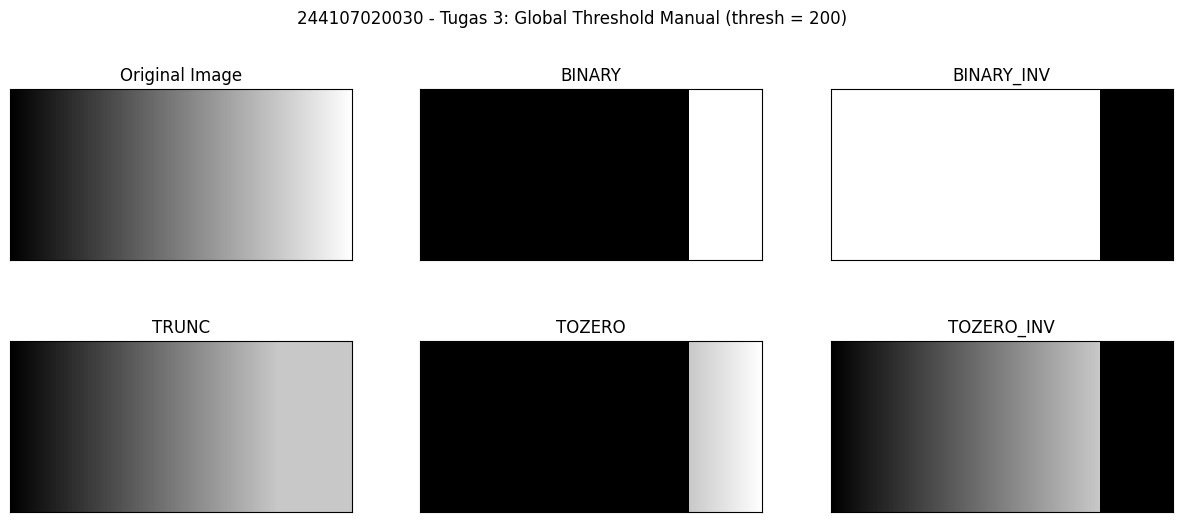

In [2]:
img = muat_citra('gradient.jpg', gray=True)
thresh = 200
maxval = 255

# 1. BINARY: piksel > thresh jadi maxval, selain itu 0
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)
# 2. BINARY_INV: piksel > thresh jadi 0, selain itu maxval
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)
# 3. TRUNC: piksel > thresh jadi thresh, selain itu tetap
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)
# 4. TOZERO: piksel > thresh tetap, selain itu 0
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)
# 5. TOZERO_INV: piksel > thresh jadi 0, selain itu tetap
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1), plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.suptitle(NIM + ' - Tugas 3: Global Threshold Manual (thresh = 200)')
plt.show()

**Jawaban Analisa:**

Threshold 200 artinya hanya piksel yang lebih terang dari 200 (sekitar 21% bagian paling kanan gradasi) yang dianggap objek.

BINARY: bagian kanan putih, sisanya hitam. BINARY_INV kebalikannya. TRUNC: nilai di atas 200 dipotong jadi 200, jadi bagian kanan abu-abu rata dan bagian kiri tetap gradasi asli. TOZERO: bagian kiri (<= 200) jadi hitam, bagian kanan tetap gradasi. TOZERO_INV: bagian kiri tetap gradasi, bagian kanan jadi hitam.

BINARY dan BINARY_INV menghasilkan citra biner murni, sedangkan TRUNC, TOZERO, dan TOZERO_INV masih menyimpan sebagian nilai keabuan asli.

**Tugas 4. Adaptive Threshold Manual (Mean dan Gaussian)**

Dibuat tanpa `cv.threshold()`, `cv.adaptiveThreshold()`, dan fungsi filter siap pakai. Ketentuan: global threshold manual 127, jendela 11 x 11, C = 2, sigma = 2 untuk Gaussian.

Langkahnya:
1. Hitung rata-rata lokal tiap piksel pada jendela 11 x 11. Untuk Mean dipakai integral image (cumsum), untuk Gaussian dipakai kernel Gaussian buatan sendiri.
2. Ambang lokal T(x, y) = rata-rata - C.
3. Kalau I(x, y) > T(x, y) jadi putih (255), selain itu hitam (0).

Tepi citra diperluas dengan menduplikasi piksel pinggir (`np.pad` mode edge).

[OK] sudoku-original.jpg berhasil dimuat, ukuran (423, 419)


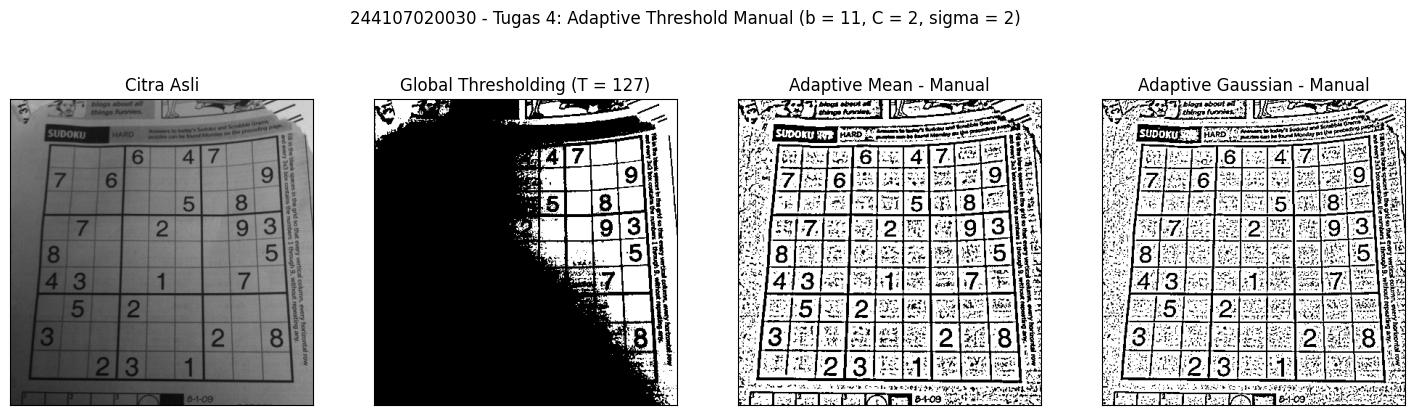

In [3]:
gray = muat_citra('sudoku-original.jpg', gray=True)
b, C, sigma = 11, 2, 2

def rata_mean(gray, b):
    """Rata-rata jendela b x b memakai integral image."""
    p = b // 2
    pad = np.pad(gray.astype(np.float64), p, mode='edge')
    integral = np.zeros((pad.shape[0] + 1, pad.shape[1] + 1))
    integral[1:, 1:] = pad.cumsum(axis=0).cumsum(axis=1)
    H, W = gray.shape
    jumlah = integral[b:b + H, b:b + W] - integral[0:H, b:b + W] - integral[b:b + H, 0:W] + integral[0:H, 0:W]
    return jumlah / (b * b)

def rata_gaussian(gray, b, sigma):
    """Rata-rata berbobot Gaussian dengan kernel Gaussian b x b buatan sendiri."""
    p = b // 2
    ax = np.arange(b) - p
    g1 = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    kernel = np.outer(g1, g1)
    kernel /= kernel.sum()                      # jumlah elemen kernel = 1
    pad = np.pad(gray.astype(np.float64), p, mode='edge')
    H, W = gray.shape
    hasil = np.zeros((H, W))
    for k1 in range(b):
        for k2 in range(b):
            hasil += kernel[k1, k2] * pad[k1:k1 + H, k2:k2 + W]
    return hasil

def adaptive_manual(gray, rata, C):
    T = np.round(rata) - C                      # T(x,y) = rata-rata - C
    return np.where(gray > T, 255, 0).astype(np.uint8)

th1 = np.where(gray > 127, 255, 0).astype(np.uint8)                       # global threshold manual
th2 = adaptive_manual(gray, rata_mean(gray, b), C)                        # adaptive mean
th3 = adaptive_manual(gray, rata_gaussian(gray, b, sigma), C)             # adaptive gaussian

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(18, 5))
for i in range(len(citra2)):
    plt.subplot(1, 4, i + 1), plt.imshow(citra2[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.suptitle(NIM + ' - Tugas 4: Adaptive Threshold Manual (b = 11, C = 2, sigma = 2)')
plt.show()

**Jawaban Analisa:**

Pada citra Sudoku yang separuhnya gelap, global threshold 127 gagal. Area gelap nilainya di bawah 127 semua sehingga jadi blok hitam dan angka di area itu hilang. Satu nilai T tidak bisa cocok untuk area terang dan gelap sekaligus.

Adaptive threshold menghitung ambang tiap piksel dari tetangganya, jadi angka dan garis di area gelap tetap muncul. Mean memberi bobot sama ke seluruh jendela 11x11, sedangkan Gaussian memberi bobot lebih besar ke piksel dekat pusat. Hasil keduanya mirip, dan dengan C = 2 masih ada bintik noise di area polos. Kalau C dinaikkan bintiknya berkurang, tapi garis tipis berisiko ikut hilang.

**Tugas 5A. Otsu Thresholding Manual (tanpa library)**

Fungsi `otsu` mencari T yang memaksimalkan between-class variance (setara meminimalkan within-class variance):
1. Hitung histogram 256 level, lalu probabilitas p(i).
2. Hitung bobot kumulatif w0(t) dan mean kumulatif untuk semua t dengan cumsum.
3. Between-class variance = w0 x w1 x (mu0 - mu1)^2.
4. T = nilai t dengan between-class variance terbesar. Piksel > T jadi 255, sisanya 0.

Hasilnya dibandingkan dengan `cv.THRESH_OTSU` dan global threshold 127 pada citra lena_gs_lc2.jpg.

Catatan: folder data praktikum dari dosen hanya berisi lena.jpg, tidak ada lena_gs_lc2.jpg. Jadi citra low contrast dibuat dari lena.jpg: dibaca grayscale, lalu intensitasnya dirapatkan ke rentang 85 sampai 108 (sesuai penjelasan modul). Karena itu nilai Otsu bisa sedikit beda dari contoh modul.

[!] lena_gs_lc2.jpg tidak ditemukan, dibuat otomatis
Threshold Otsu manual     : 95
Threshold Otsu library    : 95
Piksel beda manual-library: 0


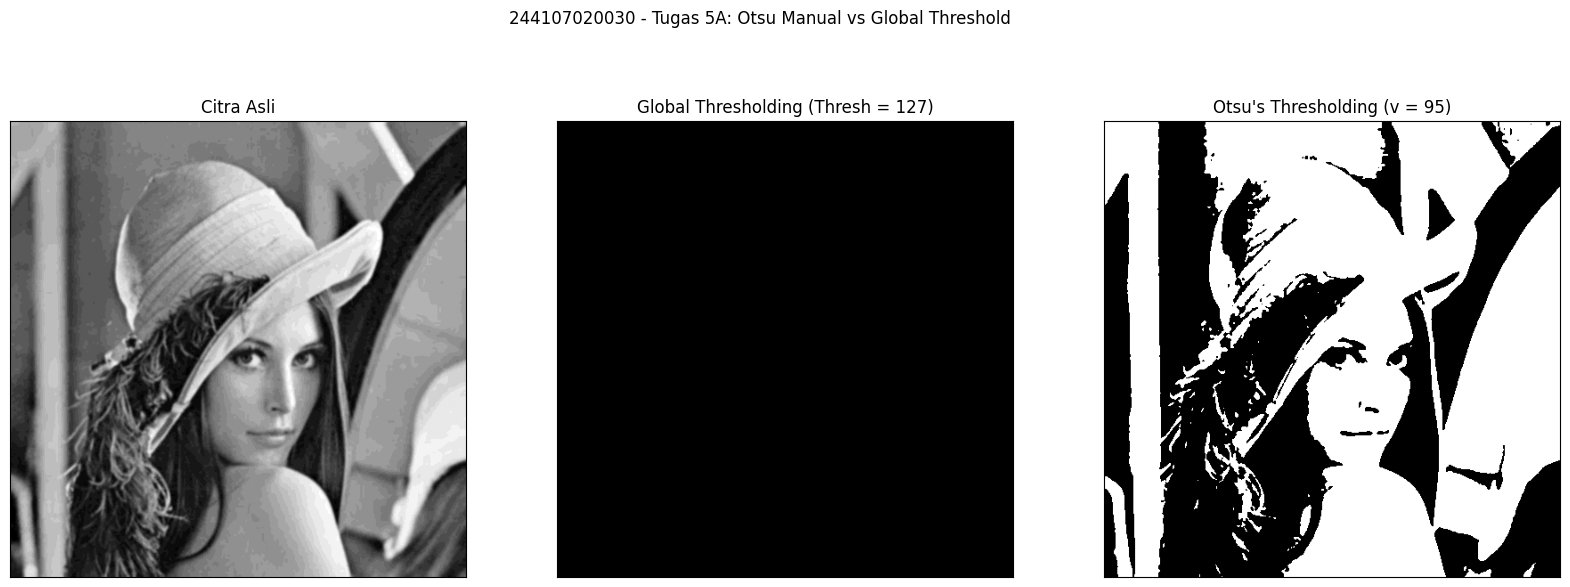

In [4]:
img = muat_citra('lena_gs_lc2.jpg', gray=True)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    w0 = np.cumsum(p)                                   # bobot background (level <= t)
    mu = np.cumsum(np.arange(256) * p)                  # jumlah i * p(i) sampai t
    muT = mu[-1]
    with np.errstate(divide='ignore', invalid='ignore'):
        between = (muT * w0 - mu) ** 2 / (w0 * (1 - w0))    # sama dengan w0 * w1 * (mu0 - mu1)^2
    between = np.nan_to_num(between)
    final_thresh = int(np.argmax(between))
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

# pembanding dengan library
ret_lib, otsu_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Threshold Otsu manual     :', otsu_thresh)
print('Threshold Otsu library    :', int(ret_lib))
print('Piksel beda manual-library:', int((otsu_biner != otsu_lib).sum()))

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 7))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.suptitle(NIM + ' - Tugas 5A: Otsu Manual vs Global Threshold')
plt.show()

**Pertanyaan:** Mengapa hasil Binary Thresholding semua bernilai 0 atau hitam semuanya? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?

Intensitas minimum : 85
Intensitas maksimum : 108
Jumlah piksel > 127 : 0 dari 262144


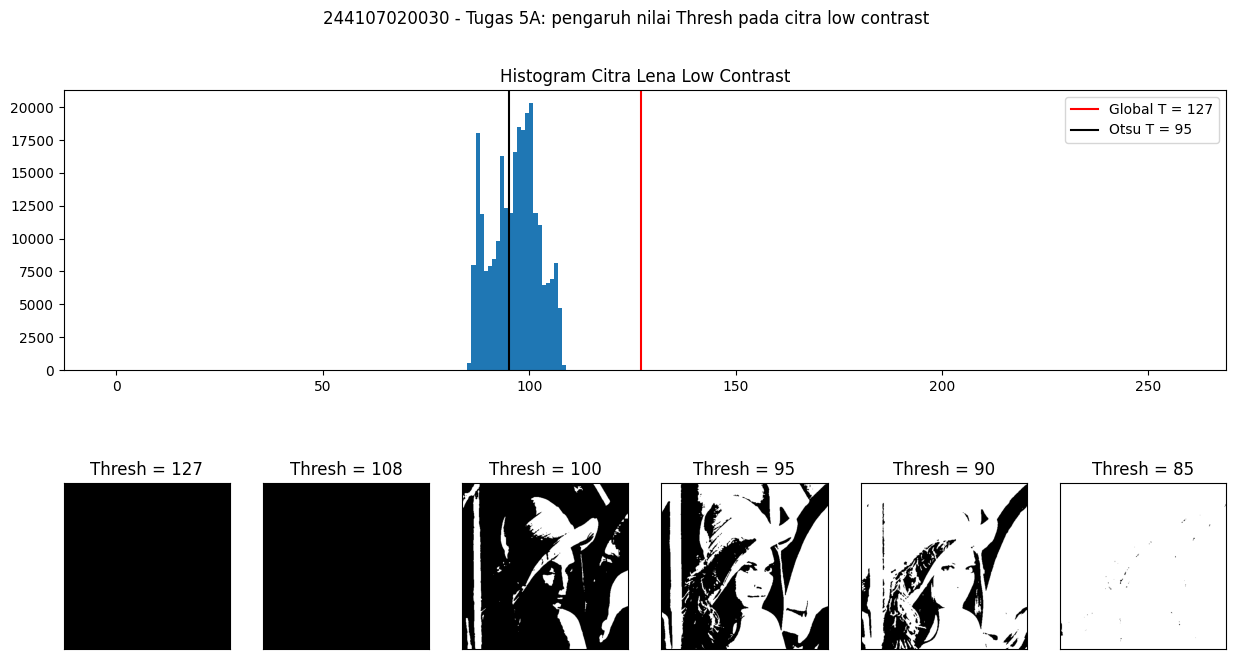

In [5]:
print('Intensitas minimum :', blur.min())
print('Intensitas maksimum :', blur.max())
print('Jumlah piksel > 127 :', int((blur > 127).sum()), 'dari', blur.size)

plt.figure(figsize=(15, 8))
plt.subplot(2, 1, 1)
plt.hist(blur.ravel(), bins=256, range=(0, 256))
plt.axvline(127, color='red', label='Global T = 127')
plt.axvline(otsu_thresh, color='black', label='Otsu T = ' + str(otsu_thresh))
plt.title('Histogram Citra Lena Low Contrast')
plt.legend()

uji = [127, int(blur.max()), otsu_thresh + 5, otsu_thresh, otsu_thresh - 5, int(blur.min())]
for i, T in enumerate(uji):
    plt.subplot(2, len(uji), len(uji) + i + 1)
    plt.imshow(np.where(blur > T, 255, 0), 'gray', vmin=0, vmax=255)
    plt.title('Thresh = ' + str(T))
    plt.xticks([]), plt.yticks([])
plt.suptitle(NIM + ' - Tugas 5A: pengaruh nilai Thresh pada citra low contrast')
plt.show()

**Jawaban Analisa:**

Citra Lena ini low contrast. Dari keluaran, intensitas minimum 85 dan maksimum 108, jadi seluruh piksel hanya ada di rentang sempit 85 sampai 108 (di histogram semuanya menumpuk di sisi kiri, jauh dari garis merah 127). Pada gambar "Citra Asli" Lena tampak kontras normal karena matplotlib otomatis meregangkan tampilan, padahal nilai aslinya hanya 85 sampai 108. Threshold 127 berada di kanan semua piksel, jumlah piksel yang > 127 adalah 0. Aturan BINARY menyebut piksel > thresh jadi putih, selain itu 0, sehingga semua piksel jadi 0 dan gambarnya hitam semua.

Supaya Lena masih terlihat, Thresh harus berada di dalam rentang intensitas citra. Secara teori Thresh harus di antara 85 dan 107, karena di luar itu semua piksel jadi satu warna. Dari percobaan di gambar, Thresh 108 hitam semua dan Thresh 85 hampir putih semua, sedangkan Thresh 90, 95, dan 100 masih menampilkan Lena dengan jelas. Jadi Thresh yang paling layak sekitar 90 sampai 100. Nilai paling pas adalah hasil Otsu, yaitu 95 pada citra ini (modul menulis 93 pada citra miliknya, selisihnya kecil karena citra low contrast di sini dibuat sendiri dari lena.jpg).

Otsu manual menghasilkan T yang sama dengan library (95) dan 0 piksel berbeda, jadi fungsinya sudah benar.

**Tugas 5B. Otsu vs Global Threshold pada KTP (ktp_fulan.jpg)**

Citra KTP dibaca keabuan, lalu dibandingkan global threshold 127 dengan Otsu manual.

[OK] ktp_fulan.jpg berhasil dimuat, ukuran (458, 694)


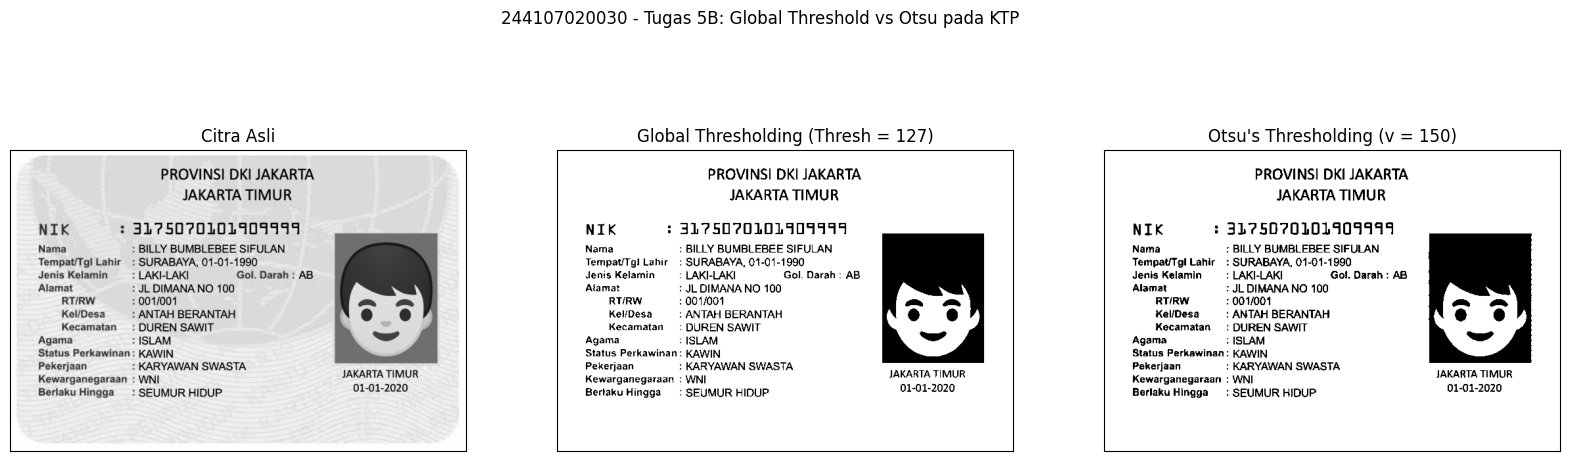

Threshold Otsu KTP : 150
Piksel hitam global 127 : 12.06%
Piksel hitam Otsu       : 12.90%


In [6]:
img = muat_citra('ktp_fulan.jpg', gray=True)
thresh = 127

otsu_biner, otsu_thresh = otsu(img)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(img, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [img, th1, otsu_biner]

plt.figure(figsize=(20, 6))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.suptitle(NIM + ' - Tugas 5B: Global Threshold vs Otsu pada KTP')
plt.show()

print('Threshold Otsu KTP :', otsu_thresh)
print('Piksel hitam global 127 : %.2f%%' % (100 * (th1 == 0).mean()))
print('Piksel hitam Otsu       : %.2f%%' % (100 * (otsu_biner == 0).mean()))

**Jawaban Analisa:**

KTP punya latar terang dan tulisan serta foto yang gelap, jadi histogramnya terdiri dari dua kelompok dan kedua metode sama-sama bisa memisahkan tulisan dari latar. Ini beda dengan Lena low contrast yang gagal total di global 127.

Dari keluaran, T Otsu pada KTP ini 150 (modul menulis 166 untuk file KTP miliknya, bedanya karena file atau ukuran citra yang tidak sama). Persentase piksel hitam hampir sama, yaitu 12,06% untuk global 127 dan 12,90% untuk Otsu. Jadi pada KTP ini hasil kedua metode mirip. Selisihnya hanya sekitar 2.700 piksel (0,84% citra) dan terlihat terutama di tepi huruf, khususnya tulisan label berwarna abu-abu (Nama, Tempat/Tgl Lahir, Status Perkawinan, dan seterusnya) serta angka NIK. Area foto hampir sama. Itu wajar karena latar KTP sangat terang dan tulisan sangat gelap sehingga T berapa pun di antara keduanya memberi hasil yang hampir sama.

Perbedaan pentingnya: global threshold memakai angka tetap 127 tanpa melihat isi citra, sedangkan Otsu mencari T sendiri dari histogram. Pada KTP yang kontrasnya tinggi keduanya cukup, tapi pada citra yang kontrasnya rendah seperti Lena hanya Otsu yang berhasil.

**Tugas 6A. Segmentasi Berbasis Region (Region Growing Manual) pada data.coins()**

Region growing dibuat sendiri memakai antrian (`deque`). Cara kerjanya:
1. Masukkan piksel seed ke antrian dan tandai sebagai anggota region.
2. Ambil satu piksel dari antrian, periksa 4 tetangganya (atas, bawah, kiri, kanan).
3. Tetangga yang belum masuk region dan selisih intensitasnya dengan seed <= T ikut masuk region dan dimasukkan ke antrian.
4. Berhenti kalau antrian kosong.

Tiga seed: di dalam koin, di latar, dan tepat di tepi koin (koin kiri atas). Tiap seed dijalankan dengan T = 5, 20, dan 60 sehingga hasilnya grid 3 x 3.

Seed Dalam koin (baris, kolom) = (53, 46)  | intensitas : 176
Seed Latar      (baris, kolom) = (90, 20)  | intensitas : 95
Seed Tepi koin  (baris, kolom) = (55, 31)  | intensitas : 202


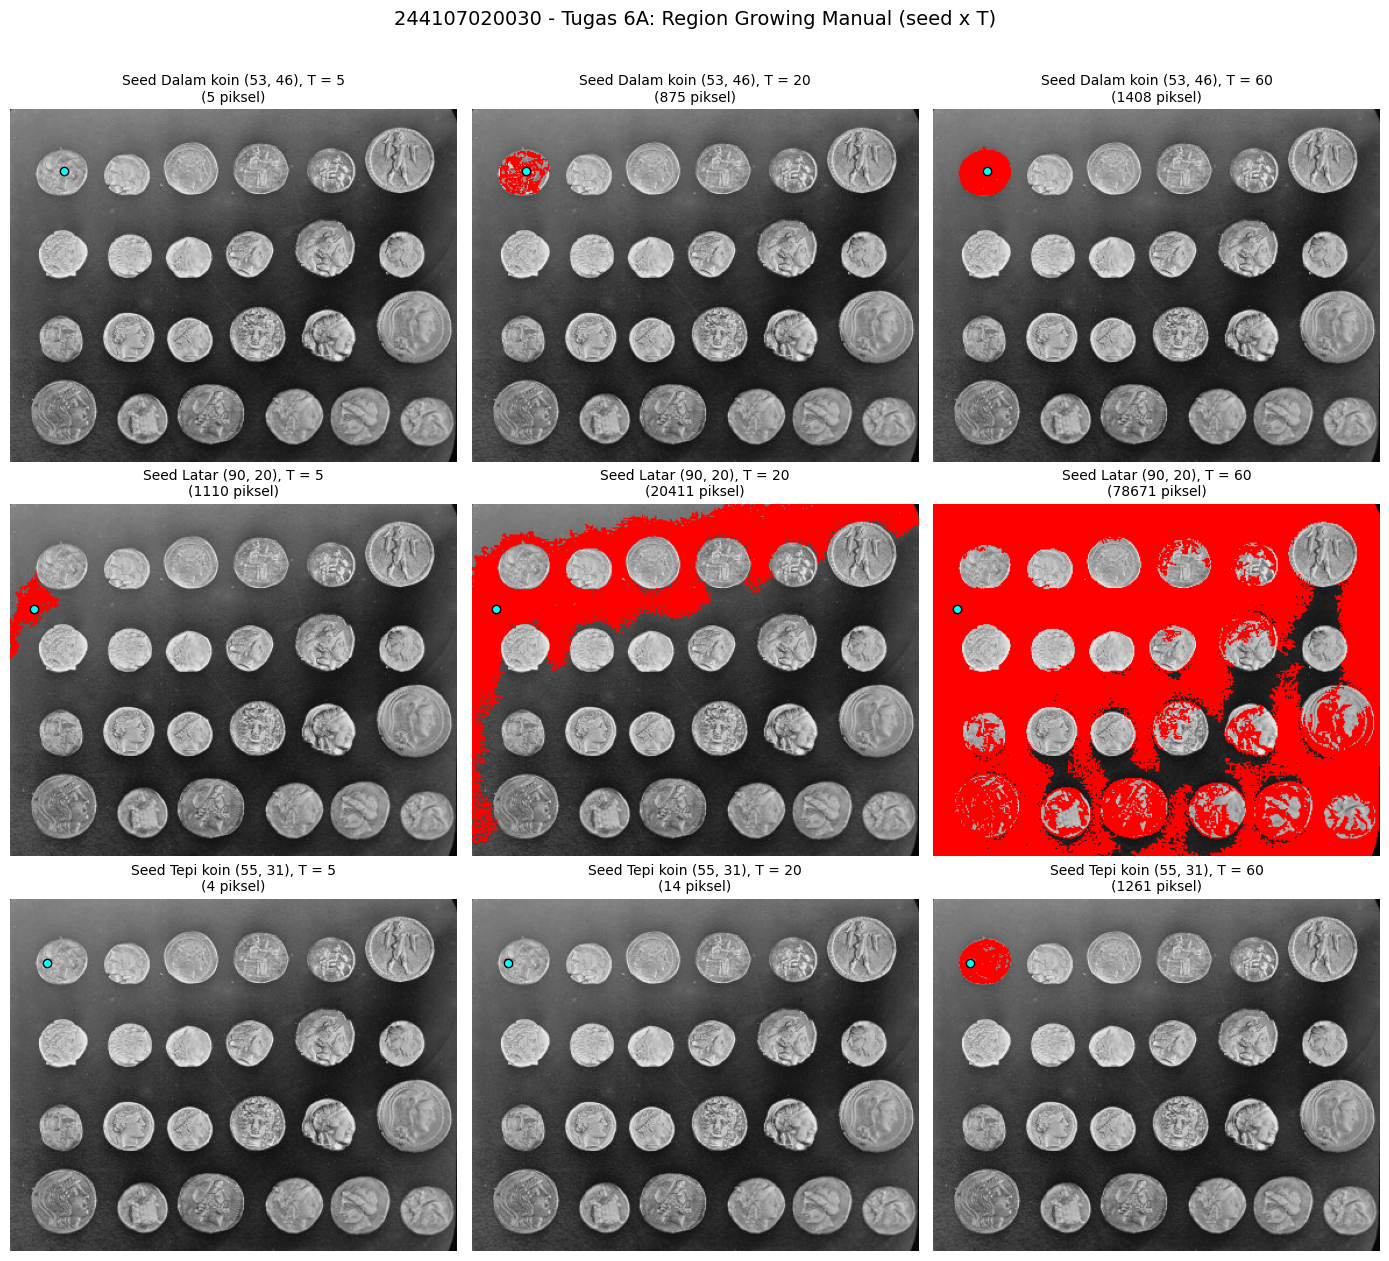

In [7]:
img = data.coins()                     # grayscale, 303 x 384

# seed (baris, kolom)
seeds = {'Dalam koin': (53, 46),          # pusat koin kiri atas
         'Latar'     : (90, 20),               # latar gelap di sisi kiri
         'Tepi koin' : (55, 31)}               # batas koin dan latar
nilai_T = [5, 20, 60]

for nama, s in seeds.items():
    print('Seed %-10s (baris, kolom) = %-9s | intensitas : %d' % (nama, s, img[s]))


def region_growing(gray, seed, T):
    H, W = gray.shape
    arah = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # 4 tetangga
    acuan = int(gray[seed])
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    antrian = deque([seed])
    while antrian:
        y, x = antrian.popleft()
        for dy, dx in arah:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                if abs(int(gray[ny, nx]) - acuan) <= T:
                    mask[ny, nx] = True
                    antrian.append((ny, nx))
    return mask


def tampil_grid(fungsi, suptitle):
    """Grid 3x3: baris = seed, kolom = T. fungsi(seed, T) mengembalikan mask region."""
    semua = {}
    fig, axs = plt.subplots(3, 3, figsize=(14, 13))
    for i, (nama, s) in enumerate(seeds.items()):
        for j, T in enumerate(nilai_T):
            mask = fungsi(s, T)
            semua[(nama, T)] = mask
            rgb = np.stack([img] * 3, axis=-1)
            rgb[mask] = (255, 0, 0)                              # region ditandai merah
            axs[i, j].imshow(rgb)
            axs[i, j].plot(s[1], s[0], 'o', color='cyan', markersize=6, markeredgecolor='black')
            axs[i, j].set_title('Seed %s %s, T = %d\n(%d piksel)' % (nama, s, T, mask.sum()), fontsize=10)
            axs[i, j].axis('off')
    fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.965])
    plt.show()
    return semua


hasil_manual = tampil_grid(lambda s, T: region_growing(img, s, T), NIM + ' - Tugas 6A: Region Growing Manual (seed x T)')

**Jawaban Analisa:**

Seed di dalam koin (di pusat koin kiri atas): T = 5 hanya mengambil 5 piksel (bercak kecil) karena permukaan koin bertekstur. T = 20 mengambil 875 piksel dan menutup sebagian besar koin tapi masih berlubang. T = 60 mengambil 1408 piksel dan menutup seluruh koin itu, bahkan mulai sedikit bocor ke latar di sekitar tepinya, tapi koin lain belum ikut terambil.

Seed di latar: karena latar homogen, T = 5 sudah mengambil 1110 piksel, T = 20 mengambil 20411 piksel, dan T = 60 mengambil 78671 piksel (sekitar dua pertiga citra) karena region menembus ke koin-koin. Seed di tepi koin paling tidak stabil: hanya 4 dan 14 piksel pada T = 5 dan 20, lalu 1261 piksel pada T = 60, karena hasilnya bergantung pada intensitas piksel seed yang kebetulan ada di batas koin dan latar.

Jadi hasil region growing sangat dipengaruhi posisi seed dan nilai T. T terlalu kecil menghasilkan bercak, T terlalu besar membuat region bocor ke objek lain.

**Tugas 6B. Region Growing dengan skimage.segmentation.flood()**

`flood` menghasilkan mask dari piksel yang terhubung dengan seed dan intensitasnya masih dalam toleransi terhadap intensitas seed. `connectivity=1` berarti 4 tetangga, sama dengan fungsi manual di 6A.

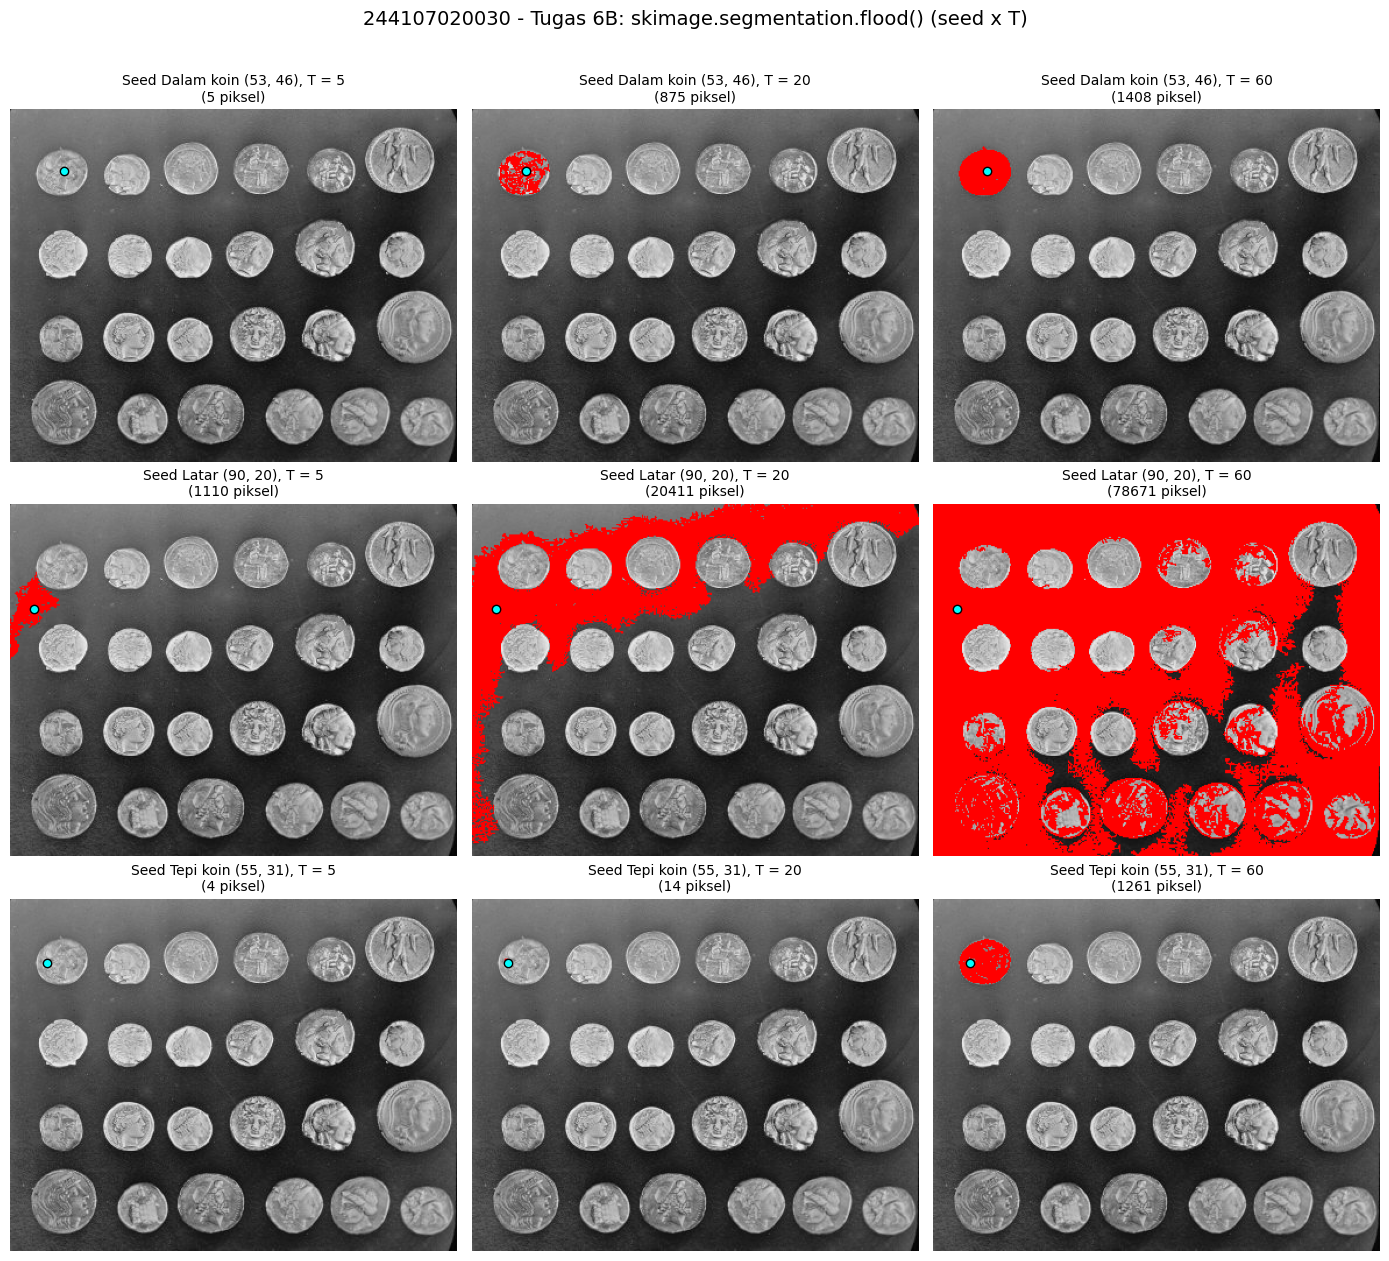

Seed Dalam koin T = 5   :      5 piksel | sama dengan manual: True
Seed Dalam koin T = 20  :    875 piksel | sama dengan manual: True
Seed Dalam koin T = 60  :   1408 piksel | sama dengan manual: True
Seed Latar      T = 5   :   1110 piksel | sama dengan manual: True
Seed Latar      T = 20  :  20411 piksel | sama dengan manual: True
Seed Latar      T = 60  :  78671 piksel | sama dengan manual: True
Seed Tepi koin  T = 5   :      4 piksel | sama dengan manual: True
Seed Tepi koin  T = 20  :     14 piksel | sama dengan manual: True
Seed Tepi koin  T = 60  :   1261 piksel | sama dengan manual: True

Seed (121, 63), tolerance 20 : 177 piksel


In [8]:
# Segmentasi menggunakan fungsi siap pakai
hasil_flood = tampil_grid(lambda s, T: flood(img, seed_point=s, tolerance=T, connectivity=1),
                          NIM + ' - Tugas 6B: skimage.segmentation.flood() (seed x T)')

for (nama, T), mask in hasil_flood.items():
    sama = np.array_equal(mask, hasil_manual[(nama, T)])
    print('Seed %-10s T = %-3d : %6d piksel | sama dengan manual: %s' % (nama, T, mask.sum(), sama))

# Contoh dari modul: seed (121, 63), tolerance 20
region = flood(img, seed_point=(121, 63), tolerance=20, connectivity=1)
print('\nSeed (121, 63), tolerance 20 :', int(region.sum()), 'piksel')

**Jawaban Analisa:**

Hasil `flood` sama persis dengan region growing manual di 6A untuk semua kombinasi seed dan T (jumlah piksel sama, misalnya 5, 875, dan 1408 untuk seed dalam koin), terbukti dari keluaran `sama dengan manual: True`. Aturannya memang sama: piksel masuk region kalau terhubung dengan seed dan selisih intensitasnya dengan seed tidak lebih dari tolerance.

Bedanya `flood` lebih singkat karena tinggal satu pemanggilan fungsi, tanpa menulis antrian sendiri. Parameter `connectivity=1` berarti 4 tetangga, sama dengan fungsi manual di 6A, sehingga hasilnya identik.

**Tugas 7. Segmentasi Warna dengan K-Means (hanya warna biru)**

Langkahnya:
1. Citra KTP diubah ke RGB, tiap piksel jadi satu titik (R, G, B), lalu dikelompokkan dengan K-Means (K = 8).
2. Warna pusat (centroid) tiap cluster diubah ke HSV.
3. Cluster biru dipilih dengan rentang dari modul: `kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))`.
4. Piksel yang cluster-nya biru dipertahankan, sisanya dihitamkan.

K-Means dilatih memakai sampel 50 ribu piksel supaya cepat, lalu semua piksel diberi label.

[OK] ktp_fulan.jpg berhasil dimuat, ukuran (458, 694, 3)
 Cluster   R   G   B   H   S   V Biru
       0 136 148 156 102  33 156   ya
       1 218 239 248  99  31 248   ya
       2  15  16  17 105  30  17    -
       3 215  70  51   3 195 215    -
       4 195 225 245 102  52 245   ya
       5 240 211 172  17  72 240    -
       6 253 254 254  90   1 254    -
       7  59  61  63 105  16  63    -
Kelompok biru (indeks cluster) : [0, 1, 4]


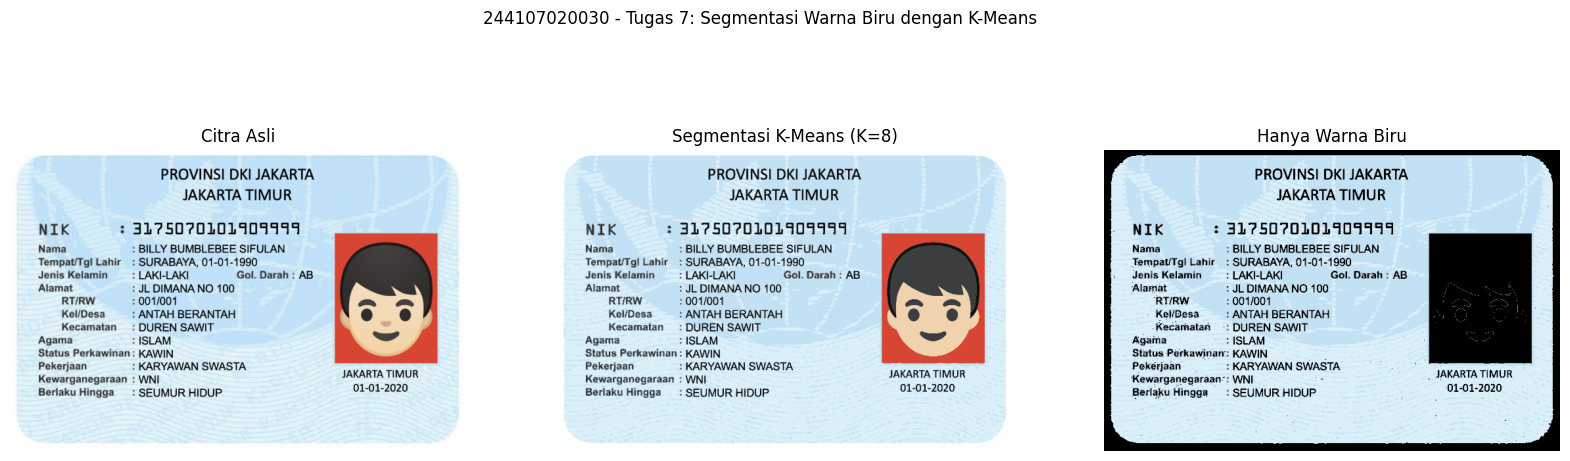

In [9]:
img = muat_citra('ktp_fulan.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = np.float32(img.reshape((-1, 3)))

# Tentukan jumlah cluster
k = 8
rng = np.random.default_rng(42)
sampel = Z[rng.choice(len(Z), size=min(50000, len(Z)), replace=False)]
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(sampel)

# Dapatkan label dan pusat cluster
labels = kmeans.predict(Z)
centers = np.uint8(np.round(kmeans.cluster_centers_))
segmented_img = centers[labels].reshape(img.shape)

# Pusat cluster diubah ke HSV, lalu pilih cluster biru
hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
H, S, V = hsv[:, 0], hsv[:, 1], hsv[:, 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))[0]

tabel = pd.DataFrame({'Cluster': range(k), 'R': centers[:, 0], 'G': centers[:, 1], 'B': centers[:, 2],
                      'H': H, 'S': S, 'V': V, 'Biru': ['ya' if i in kelompok_biru else '-' for i in range(k)]})
print(tabel.to_string(index=False))
print('Kelompok biru (indeks cluster) :', kelompok_biru.tolist())

# Hanya warna biru, selain itu hitam
mask_biru = np.isin(labels, kelompok_biru).reshape(img.shape[:2])
hanya_biru = segmented_img.copy()
hanya_biru[~mask_biru] = 0

titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
plt.figure(figsize=(20, 6))
for i, c in enumerate([img, segmented_img, hanya_biru]):
    plt.subplot(1, 3, i + 1), plt.imshow(c)
    plt.title(titles[i])
    plt.axis('off')
plt.suptitle(NIM + ' - Tugas 7: Segmentasi Warna Biru dengan K-Means')
plt.show()

**Jawaban Analisa:**

K-Means mengelompokkan piksel KTP berdasarkan kemiripan warna RGB, dan tiap cluster diwakili satu warna pusat. Dari tabel keluaran, ada 3 cluster yang pusatnya masuk rentang biru (H 85 sampai 130, S >= 25, V >= 40), yaitu yang bertanda ya di kolom Biru (biru keabu-abuan sampai biru muda). Piksel di cluster itu dipertahankan, sedangkan cluster lain (hitam, abu gelap, merah, krem, putih) dihitamkan. Hasilnya latar kartu yang biru muda tetap tampil, foto merah jadi hitam, dan area putih di luar kartu juga jadi hitam.

Rentang H 85 sampai 130 dipilih karena latar KTP biru muda kebiruan. S >= 25 membuang warna putih atau abu-abu yang hampir tanpa warna (cluster putih punya S = 1), dan V >= 40 membuang warna yang terlalu gelap (cluster hitam teks punya V = 17).

K = 8 dipakai sesuai modul. K terlalu kecil bisa menyatukan biru dengan warna lain (under-segmentation), K terlalu besar memecah latar yang sama jadi banyak cluster (over-segmentation). Kekurangan K-Means di sini adalah tidak memakai posisi piksel, jadi hasilnya tidak dijamin terhubung.

---
# **Kesimpulan**

1. Lima global threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV) bisa dibuat manual dengan NumPy mengikuti tabel ketentuan modul.
2. Global threshold dengan T tetap gagal pada citra low contrast (Lena) dan citra dengan pencahayaan tidak merata (Sudoku).
3. Adaptive threshold memakai ambang lokal (rata-rata jendela dikurangi C) sehingga tahan terhadap bayangan.
4. Otsu menentukan T otomatis dari histogram dan hasilnya sama dengan `cv.THRESH_OTSU`.
5. Region growing dipengaruhi posisi seed dan nilai T, dan hasil fungsi manual sama dengan `flood()`.
6. K-Means bisa dipakai untuk memisahkan warna tertentu (biru pada KTP) dengan bantuan rentang HSV pada centroid.